# **MOVIMIENTO BROENIANO CON DERIVA**
Elaborado por: Jorge Luis Magaña Pichardo

Ejercicio: Encuentre la probabilidad de que el movimiento browniano con parámetro deriva, $\mu =0.6$, y $\sigma^2 =0.25$, tome valores entre 1 y 3 al tiempo 4.

### **Solución analítica:**

El ejercicio resuelto analíticamente está dado por:

$X_t=0.6t+0.5B_t$, sustituyendo t=4 tenemos las siguiente expresión:
$$P(1<X_4<3) =P(1<2.4+\frac{1}{2}B_4<3)$$

$$=P(-1.4<\frac{1}{2}B_4<0.6)$$

$$=P(-2.8<B_4<1.2)$$

$$=\int_{-2.8}^{1.2} \frac{1}{\sqrt{2*4*π}}e^{-\frac{x^2}{8}}dx$$

$$=0.645$$

El código queda como:

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random as r

Definimos un movimiento browniano:

In [5]:
def brownie(T,L):
    avr = []
    w_0 = 0
    dt = T/L
    for _ in range(1,L):
        dw = r.gauss(0,1)
        w_1 = w_0 + np.sqrt(dt)*dw
        avr.append(w_1)
        
        w_0 = w_1
    avr.insert(0,0)
    return avr

Hacemos el derivado:

In [6]:
def deriva(mu, sigma, T, n):
  A = np.array(brownie(T, n))
  t = np.linspace(0, T, n)

  veo = mu * t + sigma * A

  return veo.tolist() 

In [ ]:
def prob(mu, sigma, T, n, N):
  conteo = 0

  for _ in range(N):
    veo = deriva(mu, sigma, T, n)
    valor_final = veo[-1] #se usa el útimo valor de cada deriva q se calculó

    if 1 <= valor_final <= 3:
      conteo += 1

  # Calculamos la probabilidad
  probabilidad = conteo / N
  return print("la probabilidad de que el MB tome valores entre 1 y 3 al tiempo 4 es:",probabilidad)

In [6]:
prob(0.6,0.5,4,1000,10000)


la probabilidad de que el MB tome valores entre 1 y 3 al tiempo 4 es: 0.644


Notemos que la solución analítica fue la misma que la solución simulada.

# **MOVIMIENTO BROWNIANO GEOMÉTRICO**

In [1]:
def geo(mu, sigma, T, n):
  A = np.array(brownie(T, n))
  t = np.linspace(0, T, n)

  veo = np.exp((mu - (sigma**2)/2)*t + sigma * A)

  return veo.tolist()

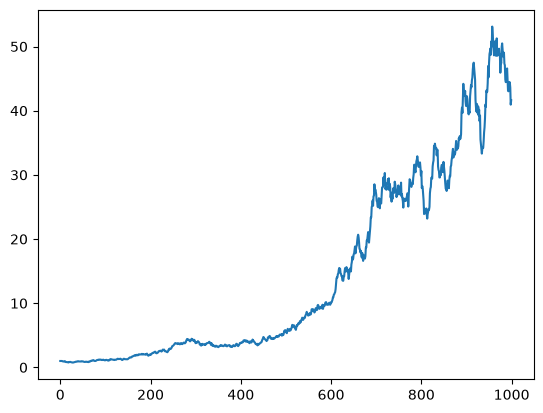

In [8]:
G0 = geo(0.6,0.5,4,1000)
plt.plot(G0)